<a href="https://colab.research.google.com/github/kansweldone/SRMMarks/blob/main/finetune_lawbot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: check the GPU ( Tesla T4)

In [1]:
!nvidia-smi

Sun Oct 11 04:49:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Cell 2: install unsloth

In [2]:
!pip install unsloth

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.4/82.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 57.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 67.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 99.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 127.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 124.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 124.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 26.4 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing inst

Cell 3: mount my google Drive and load the Phase 1 data



In [3]:
from google.colab import drive
drive.mount('/content/drive')

from datasets import load_dataset
DATA = '/content/drive/MyDrive/LawBot'
ds = load_dataset('json', data_files={'train': f'{DATA}/lawbot_train.jsonl',
                                      'val':   f'{DATA}/lawbot_val.jsonl'})
print(ds)
print(ds['train'][0])

Mounted at /content/drive


Generating train split: 0 examples [00:00, ? examples/s]

Generating val split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['instruction', 'output', 'source', 'refs', 'split'],
        num_rows: 11576
    })
    val: Dataset({
        features: ['instruction', 'output', 'source', 'refs', 'split'],
        num_rows: 2893
    })
})
{'instruction': 'What is India according to the Union and its Territory?', 'output': 'India, that is Bharat, shall be a Union of States.', 'source': 'Constitution', 'refs': [], 'split': 'train'}


Cell 4: load Qwen2.5-1.5B in 4-bit

In [4]:
from unsloth import FastLanguageModel

MODEL = 'unsloth/Qwen2.5-1.5B-Instruct'
MAX_LEN = 512

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL,
    max_seq_length=MAX_LEN,
    load_in_4bit=True,      # QLoRA: base weights stored in 4-bit to save GPU memory
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Cell 5: add LoRA adapters

In [5]:
model = FastLanguageModel.get_peft_model(
    model,
    r=16,                   # adapter rank: size of the small trainable matrices
    lora_alpha=16,          # scaling factor for the adapter updates
    lora_dropout=0,
    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj',   # attention layers
                    'gate_proj', 'up_proj', 'down_proj'],    # feed-forward layers
    use_gradient_checkpointing='unsloth',  # trades speed for memory
    random_state=42,
)
model.print_trainable_parameters()

Unsloth 2026.10.3 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


Cell 6: build the chat text

In [6]:
SYSTEM = ("You are LawBot, an assistant for Indian law (IPC, CrPC and the Constitution of India). "
          "Answer accurately and concisely, and cite the relevant Section or Article where applicable.")

def to_text(ex):
    msgs = [{'role': 'system',    'content': SYSTEM},
            {'role': 'user',      'content': ex['instruction']},
            {'role': 'assistant', 'content': ex['output']}]
    return {'text': tokenizer.apply_chat_template(msgs, tokenize=False)}

ds_chat = ds.map(to_text)
print(ds_chat['train'][0]['text'])

Map:   0%|          | 0/11576 [00:00<?, ? examples/s]

Map:   0%|          | 0/2893 [00:00<?, ? examples/s]

<|im_start|>system
You are LawBot, an assistant for Indian law (IPC, CrPC and the Constitution of India). Answer accurately and concisely, and cite the relevant Section or Article where applicable.<|im_end|>
<|im_start|>user
What is India according to the Union and its Territory?<|im_end|>
<|im_start|>assistant
India, that is Bharat, shall be a Union of States.<|im_end|>



Cell 7: check token lengths

In [7]:
import numpy as np
lens = [len(tokenizer(t).input_ids) for t in ds_chat['train']['text']]
print(f'tokens per example -> median {int(np.median(lens))}, 99th pct {int(np.percentile(lens, 99))}, max {max(lens)}')
print('examples longer than MAX_LEN:', sum(l > MAX_LEN for l in lens))

tokens per example -> median 94, 99th pct 185, max 361
examples longer than MAX_LEN: 0


Cell 8: install the scoring libraries

In [8]:
!pip install -q evaluate rouge_score bert_score

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 6.5 MB/s eta 0:00:00


Cell 9: pick 200 validation questions and generate answers

In [9]:
import re, torch, pandas as pd
from tqdm.auto import tqdm

N_EVAL = 200
eval_set = ds['val'].shuffle(seed=42).select(range(N_EVAL))

def generate(question, max_new_tokens=128):
    msgs = [{'role': 'system', 'content': SYSTEM},
            {'role': 'user',   'content': question}]
    prompt = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    enc = tokenizer(prompt, return_tensors='pt').to('cuda')
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0, enc['input_ids'].shape[1]:], skip_special_tokens=True).strip()

FastLanguageModel.for_inference(model)          # faster generation mode
base_preds = [generate(q) for q in tqdm(eval_set['instruction'])]

pd.DataFrame({'question': eval_set['instruction'], 'gold': eval_set['output'],
              'source': eval_set['source'], 'base_pred': base_preds}
            ).to_csv(f'{DATA}/eval_base_predictions.csv', index=False)
for q, g, p in list(zip(eval_set['instruction'], eval_set['output'], base_preds))[:3]:
    print(f'Q: {q}\nGOLD: {g}\nBASE: {p}\n')

  0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Q: What does it mean when any reference to the Schedule in the Constitution of India is construed as a reference to such Schedule as so amended?
GOLD: It means that the Parliament has the power to amend the Schedule by way of addition, variation or repeal any of the provisions of this Schedule from time to time.
BASE: When a reference to the "Schedule" in the Constitution of India is construed as a reference to that Schedule as so amended, it means that the amendment made to the schedule will be considered while interpreting the constitutional provisions related to that schedule. This ensures that the constitution remains responsive to changes in society and governance over time. The principle is enshrined in Article 368 of the Constitution, which provides for amendments to the Constitution.

Q: What are the potential consequences for dishonestly misappropriating movable property or converting it to one's own use?
GOLD: Imprisonment for 2 years, or fine, or both.
BASE: If someone disho

Cell 10: scoring function, applied to the base model

In [10]:
import evaluate, numpy as np
rouge = evaluate.load('rouge')
bertscore = evaluate.load('bertscore')

SEC_RE = re.compile(r'(?<![-\w])(Section|Sec\.|Article|Art\.|Schedule|Chapter)\s+([0-9]+[A-Z]{0,2}|[IVXLC]+)\b', re.I)
CANON = {'sec.': 'Section', 'section': 'Section', 'art.': 'Article', 'article': 'Article',
         'schedule': 'Schedule', 'chapter': 'Chapter'}
def get_refs(text):
    return {f'{CANON[k.lower()]} {n.upper()}' for k, n in SEC_RE.findall(text)}

def score(preds, golds):
    rl = rouge.compute(predictions=preds, references=golds)['rougeL']
    bs = np.mean(bertscore.compute(predictions=preds, references=golds, lang='en')['f1'])
    pairs = [(get_refs(g), get_refs(p)) for g, p in zip(golds, preds) if get_refs(g)]
    cit = np.mean([len(g & p) / len(g) for g, p in pairs]) if pairs else float('nan')
    return {'rougeL': round(rl, 4), 'bertscore_f1': round(float(bs), 4),
            'citation_recall': round(float(cit), 4), 'n_with_citations': len(pairs)}

base_scores = score(base_preds, eval_set['output'])
base_scores

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'rougeL': np.float64(0.1454),
 'bertscore_f1': 0.8494,
 'citation_recall': 0.3077,
 'n_with_citations': 26}

Cell 11: set up the trainer

In [11]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported
from unsloth.chat_templates import train_on_responses_only

FastLanguageModel.for_training(model)            # switch back from inference mode
val_small = ds_chat['val'].shuffle(seed=1).select(range(300))   # for tracking validation loss

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=ds_chat['train'],
    eval_dataset=val_small,
    args=SFTConfig(
        dataset_text_field='text',
        max_length=MAX_LEN,
        per_device_train_batch_size=8,
        gradient_accumulation_steps=2,        # effective batch = 8 x 2 = 16
        num_train_epochs=1,
        learning_rate=2e-4,
        warmup_steps=20,
        lr_scheduler_type='linear',
        optim='adamw_8bit',
        weight_decay=0.01,
        fp16=not is_bfloat16_supported(),     # T4 has no bf16 -> uses fp16
        bf16=is_bfloat16_supported(),
        logging_steps=25,
        eval_strategy='steps', eval_steps=100,
        per_device_eval_batch_size=8,
        save_strategy='no',
        output_dir='/content/outputs',
        report_to='none',
        seed=42,
    ),
)

# learn only from the answer, not from the system prompt and question
trainer = train_on_responses_only(trainer,
                                  instruction_part='<|im_start|>user\n',
                                  response_part='<|im_start|>assistant\n')

# check: the trained part of example 0 should be just the answer
lab = trainer.train_dataset[0]['labels']
print(tokenizer.decode([t for t in lab if t != -100]))

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/11576 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/300 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map (num_proc=2):   0%|          | 0/11576 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/300 [00:00<?, ? examples/s]

India, that is Bharat, shall be a Union of States.<|im_end|>


Cell 12: train, then plot the loss

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 11,576 | Num Epochs = 1 | Total steps = 724
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 2 x 1) = 16
 "-____-"     Trainable parameters = 18,464,768 of 1,562,179,072 (1.18% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
100,1.497098,1.534114
200,1.503273,1.475638
300,1.385189,1.430405
400,1.369237,1.404687
500,1.313065,1.374455
600,1.328056,1.360547
700,1.306833,1.349079
724,1.306833,1.348448


Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

Training time: 16.8 min, final train loss: 1.4074


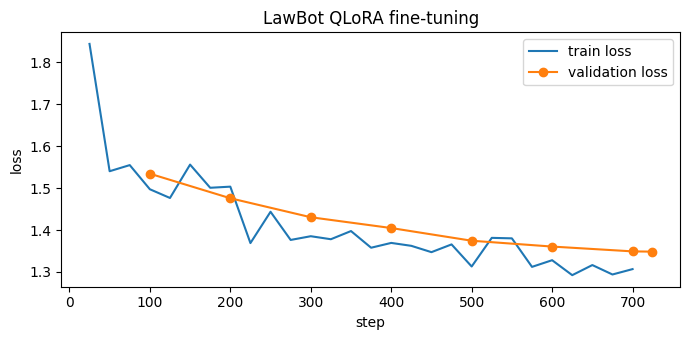

In [12]:
import matplotlib.pyplot as plt
result = trainer.train()
print(f"Training time: {result.metrics['train_runtime']/60:.1f} min, final train loss: {result.training_loss:.4f}")

logs = trainer.state.log_history
tr = [(l['step'], l['loss']) for l in logs if 'loss' in l]
ev = [(l['step'], l['eval_loss']) for l in logs if 'eval_loss' in l]
plt.figure(figsize=(7, 3.5))
plt.plot(*zip(*tr), label='train loss'); plt.plot(*zip(*ev), 'o-', label='validation loss')
plt.xlabel('step'); plt.ylabel('loss'); plt.title('LawBot QLoRA fine-tuning'); plt.legend(); plt.tight_layout()
plt.savefig(f'{DATA}/phase2_loss_curve.png', dpi=130); plt.show()

Cell 13: generate answers with the fine-tuned model on the same 200 questions

In [13]:
FastLanguageModel.for_inference(model)
ft_preds = [generate(q) for q in tqdm(eval_set['instruction'])]
ft_scores = score(ft_preds, eval_set['output'])

comparison = pd.DataFrame({'Base Qwen2.5-1.5B': base_scores, 'LawBot (QLoRA)': ft_scores})
print(comparison)

pd.DataFrame({'question': eval_set['instruction'], 'gold': eval_set['output'], 'source': eval_set['source'],
              'base_pred': base_preds, 'lawbot_pred': ft_preds}
            ).to_csv(f'{DATA}/eval_predictions_base_vs_lawbot.csv', index=False)
comparison.to_csv(f'{DATA}/phase2_eval_results.csv')

  0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

                  Base Qwen2.5-1.5B  LawBot (QLoRA)
rougeL                       0.1454          0.3168
bertscore_f1                 0.8494          0.8918
citation_recall              0.3077          0.3077
n_with_citations            26.0000         26.0000


Cell 14: compare example answers side by side


In [14]:
for i in [0, 1, 2]:
    print(f"Q: {eval_set['instruction'][i]}\nGOLD  : {eval_set['output'][i]}\nBASE  : {base_preds[i][:300]}\nLAWBOT: {ft_preds[i]}\n")

# also look at one where the gold answer cites a Section/Article
j = next(i for i, g in enumerate(eval_set['output']) if get_refs(g))
print(f"Q: {eval_set['instruction'][j]}\nGOLD  : {eval_set['output'][j]}\nBASE  : {base_preds[j][:300]}\nLAWBOT: {ft_preds[j]}")

Q: What does it mean when any reference to the Schedule in the Constitution of India is construed as a reference to such Schedule as so amended?
GOLD  : It means that the Parliament has the power to amend the Schedule by way of addition, variation or repeal any of the provisions of this Schedule from time to time.
BASE  : When a reference to the "Schedule" in the Constitution of India is construed as a reference to that Schedule as so amended, it means that the amendment made to the schedule will be considered while interpreting the constitutional provisions related to that schedule. This ensures that the constitutio
LAWBOT: It means that if there is any change made by this article in the provisions of the said Schedule, then all references to the said Schedule shall be construed as references to such Schedule as so amended.

Q: What are the potential consequences for dishonestly misappropriating movable property or converting it to one's own use?
GOLD  : Imprisonment for 2 years, or f

Cell 15: scores by source (IPC / CrPC / Constitution)

In [15]:
src = np.array(eval_set['source'])
rows = {}
for s in ['IPC', 'CrPC', 'Constitution']:
    m = src == s
    golds = [g for g, k in zip(eval_set['output'], m) if k]
    rows[s] = {'n': int(m.sum()),
               'base_rougeL': round(rouge.compute(predictions=[p for p, k in zip(base_preds, m) if k], references=golds)['rougeL'], 4),
               'lawbot_rougeL': round(rouge.compute(predictions=[p for p, k in zip(ft_preds, m) if k], references=golds)['rougeL'], 4)}
pd.DataFrame(rows).T

,n,base_rougeL,lawbot_rougeL
IPC,32.0,0.1574,0.3476
CrPC,115.0,0.1268,0.2846
Constitution,53.0,0.1784,0.3670


Cell 16: save the LoRA adapter to Drive (a required deliverable)

In [16]:
SAVE = f'{DATA}/lawbot_lora_adapter'
model.save_pretrained(SAVE)
tokenizer.save_pretrained(SAVE)
!ls -lh {SAVE}

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/LawBot/lawbot_lora_adapter/tokenizer_config.json.


total 82M
-rw------- 1 root root 1.4K Oct 11 06:06 adapter_config.json
-rw------- 1 root root  71M Oct 11 06:06 adapter_model.safetensors
-rw------- 1 root root 2.5K Oct 11 06:06 chat_template.jinja
-rw------- 1 root root 5.2K Oct 11 06:06 README.md
-rw------- 1 root root 4.4K Oct 11 06:06 tokenizer_config.json
-rw------- 1 root root  11M Oct 11 06:06 tokenizer.json
